In [1]:
import pandas as pd

In [2]:
# unique_dst_ports has some nan values
df = pd.read_csv("traffic_data.csv")

# Missing values

In [3]:
# Check for nans
#df['device_id'].isna().sum()
#df['total_bytes'].isna().sum()
#df['total_packets'].isna().sum()
#df['avg_packet_size'].isna().sum()
#df['num_connections'].isna().sum()
#df['avg_conn_duration_sec'].isna().sum()
# This one does have nans
df['unique_dst_ports'].isna().sum()
#df['unique_dst_ips'].isna().sum()

np.int64(15)

# Distributions

<Axes: >

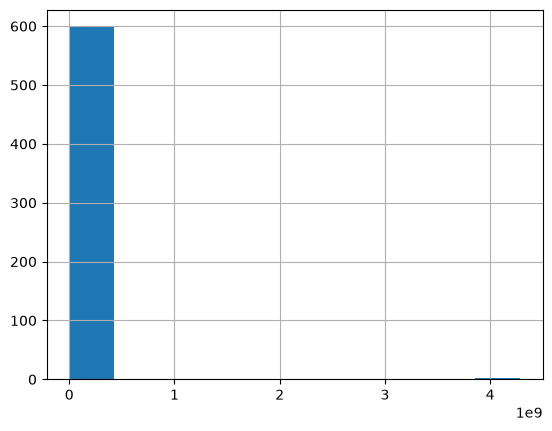

In [4]:
'''
Display a distribution of the values for
df['total_bytes'] - df['total_packets'] * df['avg_packet_size']
'''

df['difference'] = df['total_bytes'] - (df['total_packets'] * df['avg_packet_size'])
df['difference'].hist()

<Axes: >

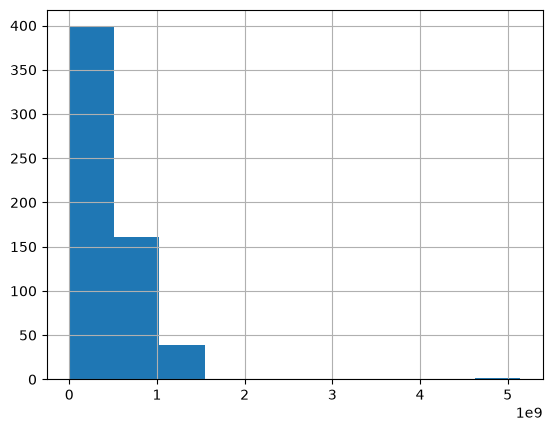

In [5]:
df['total_bytes'].hist()

<Axes: >

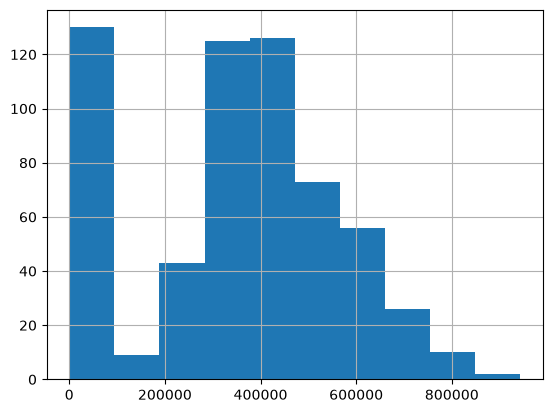

In [6]:
df['total_packets'].hist()

<Axes: >

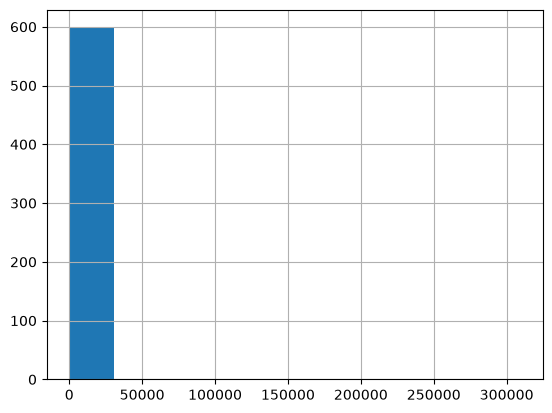

In [7]:
df['avg_packet_size'].hist()

In [8]:
df[(df['avg_packet_size'] > 20000)]

,device_id,total_bytes,total_packets,avg_packet_size,num_connections,avg_conn_duration_sec,unique_dst_ports,unique_dst_ips,tcp_ratio,night_activity_ratio,device_type,difference
128,printer_0011,3.092790e+07,100,309278.950391,8,7.168522,1.0,1,0.828598,0.0,printer,0.0


In [9]:
df['avg_packet_size'].median()

np.float64(1234.4523301979689)

<Axes: >

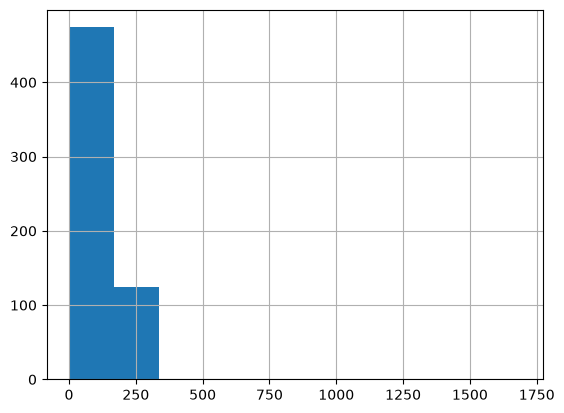

In [10]:
df['num_connections'].hist()

<Axes: >

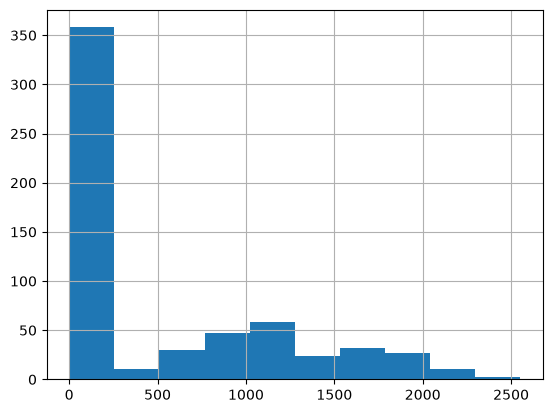

In [11]:
df['avg_conn_duration_sec'].hist()

<Axes: >

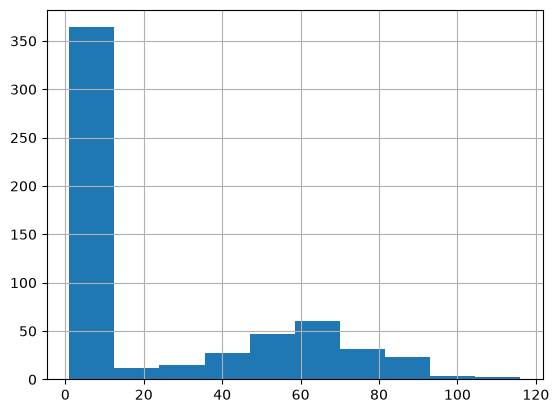

In [12]:
df['unique_dst_ports'].hist()

<Axes: >

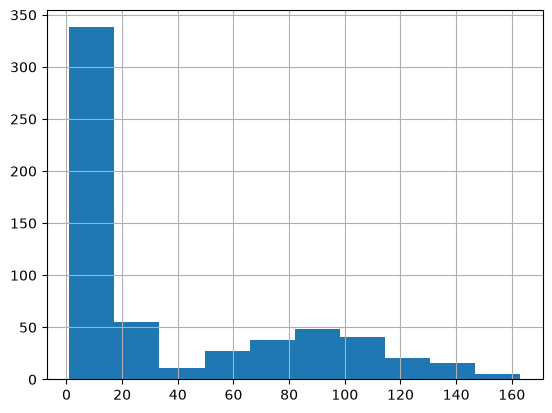

In [13]:
df['unique_dst_ips'].hist()

# Fixing outliers

In [14]:
# The difference column above (total_bytes - total_packets * avg_packet_size)
# should be ~0 for every row; rows where it isn't line up with genuine
# outliers in total_bytes itself. Confirm with a proper z-score rather than
# eyeballing the histogram -- a pooled histogram's long tail can just be a
# different device_type's normal range, not real outliers.
z_total_bytes = (df['total_bytes'] - df['total_bytes'].mean()) / df['total_bytes'].std()
outliers = df[z_total_bytes.abs() > 3]
outliers[['device_id', 'device_type', 'total_bytes', 'difference']]


,device_id,device_type,total_bytes,difference
332,laptop_0139,laptop,5.142476e+09,4.285398e+09
480,smart_tv_0036,smart_tv,5.007233e+09,4.172695e+09


# Handling NaNs

In [15]:
# Replace unique_dst_ports NaNs with each row's own device_type group mean,
# rather than the global column mean -- port counts vary a lot by device
# type (e.g. a laptop touching dozens of ports vs. a thermostat touching 2-3),
# so a global mean would systematically pull imputed rows toward "average
# device" rather than their own type's typical range.
df['unique_dst_ports'] = df.groupby('device_type')['unique_dst_ports'].transform(
    lambda s: s.fillna(s.mean())
)


In [16]:
df['unique_dst_ports'].isna().sum()

np.int64(0)

# Check class balance

<Axes: >

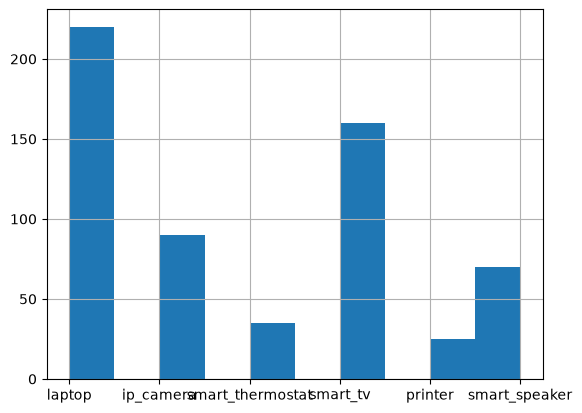

In [17]:
df['device_type'].hist()

# Modeling v1

Train a classifier to predict `device_type` from the traffic features. Use 5-fold stratified cross-validation and report average accuracy, macro precision, and macro recall.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay

# Explicit column lists, rather than "scale everything passed in" -- this is
# where a real dataset's categorical columns (e.g. protocol, OS family) would
# go in the categorical_cols list, routed to their own encoder below instead
# of being scaled. Empty for now since every feature here is numeric.
numeric_cols = [
    'total_bytes', 'total_packets', 'avg_packet_size', 'num_connections',
    'avg_conn_duration_sec', 'unique_dst_ports', 'unique_dst_ips',
    'tcp_ratio', 'night_activity_ratio',
]
categorical_cols = []

X = df[numeric_cols + categorical_cols]
y = df['device_type']


def build_pipeline(clf, numeric_cols, categorical_cols):
    """Shared impute+scale(+encode) preprocessing wrapped around any clf."""
    numeric_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='mean')),
        ('scale', StandardScaler()),
    ])

    preprocessor = ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_cols),
        # ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ])

    return Pipeline([
        ('preprocess', preprocessor),
        ('clf', clf),
    ])


def evaluate_classifier(clf, X, y, numeric_cols, categorical_cols, n_splits=5, random_state=42):
    """
    Runs stratified k-fold CV for a given (unfitted) classifier and
    prints/returns average accuracy, macro precision, and macro recall.

    Pass any unfitted sklearn-compatible classifier (LogisticRegression,
    RandomForestClassifier, xgboost.XGBClassifier, ...) -- the preprocessing
    and CV setup stays identical, only `clf` changes. `y` is label-encoded
    to integers here because some classifiers (XGBoost) require integer
    class labels 0..n_classes-1 and won't accept raw strings, unlike
    sklearn's own classifiers which accept either.
    """
    pipeline = build_pipeline(clf, numeric_cols, categorical_cols)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    y_enc = LabelEncoder().fit_transform(y)

    # Macro averaging: treats all 6 device types equally regardless of class
    # size, which matters here since laptop (220) vs printer (25) are heavily
    # imbalanced.
    scores = cross_validate(
        pipeline, X, y_enc, cv=cv,
        scoring=['accuracy', 'precision_macro', 'recall_macro'],
    )

    print(f"Accuracy:          {scores['test_accuracy'].mean():.3f} (+/- {scores['test_accuracy'].std():.3f})")
    print(f"Precision (macro): {scores['test_precision_macro'].mean():.3f} (+/- {scores['test_precision_macro'].std():.3f})")
    print(f"Recall (macro):    {scores['test_recall_macro'].mean():.3f} (+/- {scores['test_recall_macro'].std():.3f})")
    return scores


def plot_confusion_matrix_cv(clf, X, y, numeric_cols, categorical_cols, n_splits=5, random_state=42):
    """
    Confusion matrix built from out-of-fold predictions under the same
    stratified CV split as evaluate_classifier, so it reflects the same
    cross-validated performance rather than a single train/test split.
    Rows = true device_type, columns = predicted device_type; cell (i, j) =
    number of samples whose true class is i but were predicted as class j
    (the diagonal is correct predictions). `y` is label-encoded for the same
    reason as in evaluate_classifier, then predictions are decoded back to
    the original device_type strings so the plot stays readable.
    """
    pipeline = build_pipeline(clf, numeric_cols, categorical_cols)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    le = LabelEncoder()
    y_enc = le.fit_transform(y)
    y_pred_enc = cross_val_predict(pipeline, X, y_enc, cv=cv)
    y_pred = le.inverse_transform(y_pred_enc)
    ConfusionMatrixDisplay.from_predictions(y, y_pred, xticks_rotation=45)
    return y_pred



## Logistic Regression

Accuracy:          0.990 (+/- 0.008)
Precision (macro): 0.987 (+/- 0.012)
Recall (macro):    0.976 (+/- 0.022)


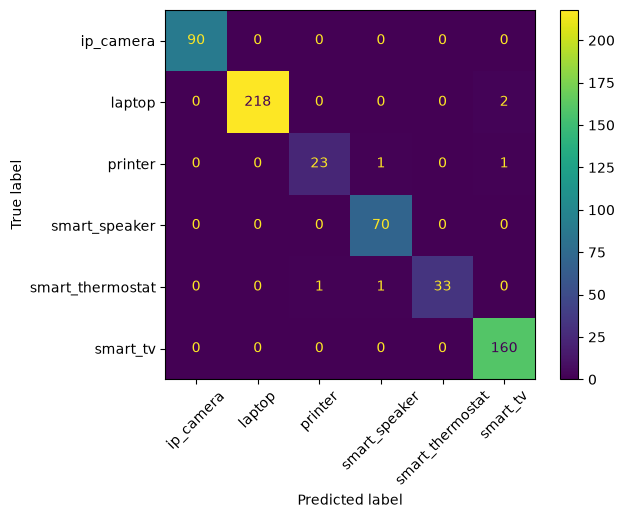

In [19]:
scores = evaluate_classifier(
    LogisticRegression(max_iter=1000), X, y, numeric_cols, categorical_cols,
)
y_pred = plot_confusion_matrix_cv(
    LogisticRegression(max_iter=1000), X, y, numeric_cols, categorical_cols,
)

## Random Forest

Accuracy:          0.998 (+/- 0.003)
Precision (macro): 0.998 (+/- 0.004)
Recall (macro):    0.999 (+/- 0.002)


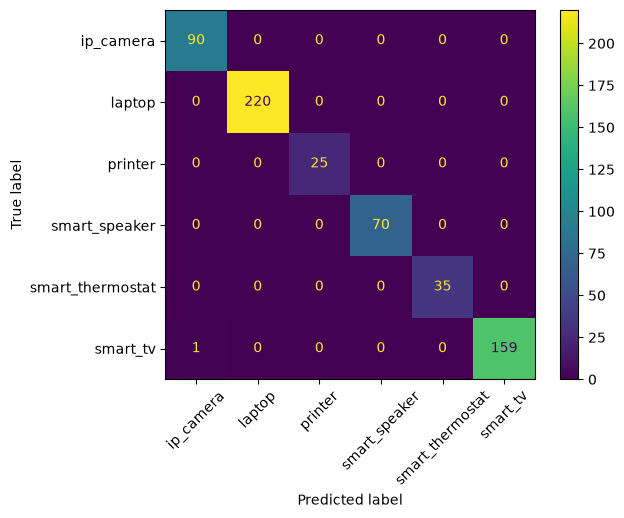

In [20]:
from sklearn.ensemble import RandomForestClassifier
scores = evaluate_classifier(RandomForestClassifier(random_state=42), X, y, numeric_cols, categorical_cols)
y_pred = plot_confusion_matrix_cv(RandomForestClassifier(random_state=42), X, y, numeric_cols, categorical_cols)


## XGBoost

Accuracy:          0.997 (+/- 0.004)
Precision (macro): 0.995 (+/- 0.008)
Recall (macro):    0.992 (+/- 0.013)


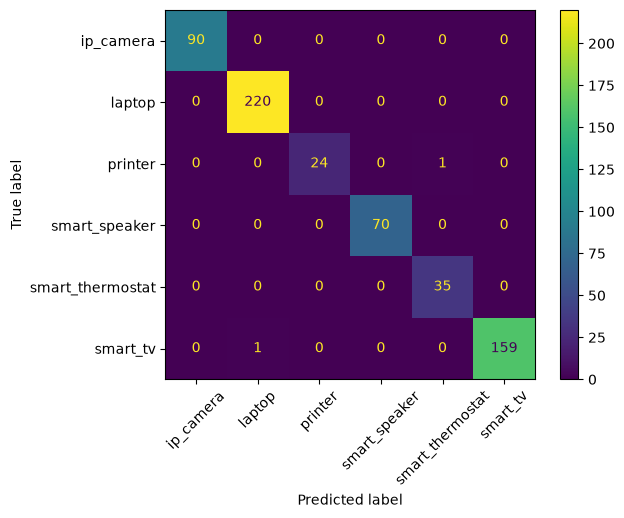

In [21]:
from xgboost import XGBClassifier
scores = evaluate_classifier(XGBClassifier(), X, y, numeric_cols, categorical_cols)
y_pred = plot_confusion_matrix_cv(XGBClassifier(), X, y, numeric_cols, categorical_cols)


## Feature importance (SHAP)

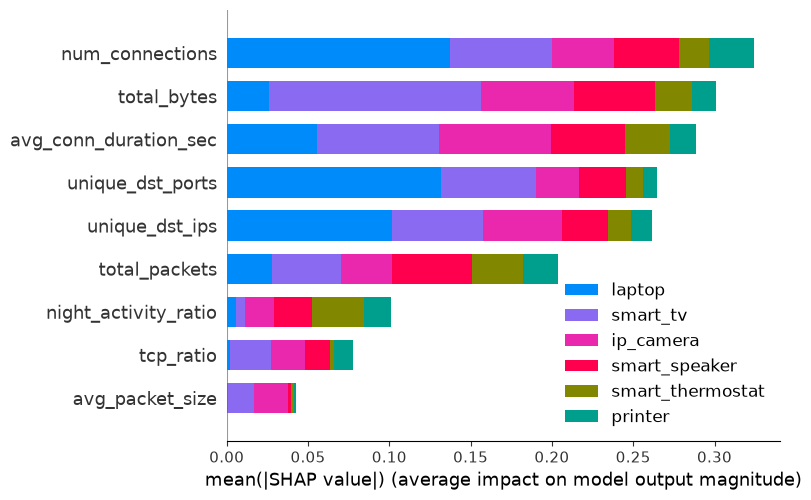

In [22]:
import shap


def plot_shap_summary(clf, X, y, numeric_cols, categorical_cols):
    """
    SHAP explains the predictions of one fitted model -- it doesn't map
    cleanly onto k-fold CV, which trains 5 *different* models (one per fold)
    rather than one. Standard practice decouples the two concerns: CV
    answers "how well does this approach generalize," which is a separate
    question from "what did the model learn." So here we fit one model on
    the FULL dataset purely for interpretation -- this is also the model
    you'd actually deploy, after CV already validated the approach
    separately. These SHAP values describe this one model's behavior, not
    an out-of-sample estimate of it (a more rigorous but more expensive
    alternative is out-of-fold SHAP, mirroring cross_val_predict above --
    worth doing if you need every sample explained by a model that never
    saw it in training).
    """
    pipeline = build_pipeline(clf, numeric_cols, categorical_cols)
    pipeline.fit(X, y)

    fitted_clf = pipeline.named_steps['clf']
    X_transformed = pipeline.named_steps['preprocess'].transform(X)
    feature_names = numeric_cols + categorical_cols  # categorical would need expansion once one-hot encoded

    # Tree models (RandomForest, XGBoost) get an exact, fast explainer with
    # no background data needed; other models (e.g. LogisticRegression) need
    # a background dataset to build their explainer against, so fall back to
    # passing one if the no-background form isn't supported for this clf.
    try:
        explainer = shap.Explainer(fitted_clf, feature_names=feature_names)
    except Exception:
        explainer = shap.Explainer(fitted_clf, X_transformed, feature_names=feature_names)
    shap_values = explainer(X_transformed)

    # Multiclass: shap_values.values is (n_samples, n_features, n_classes).
    # The classic summary_plot multiclass form wants a list of per-class
    # (n_samples, n_features) arrays, and shows one bar per class per feature.
    values_list = [shap_values.values[:, :, i] for i in range(shap_values.values.shape[2])]
    shap.summary_plot(
        values_list, X_transformed,
        feature_names=feature_names, class_names=list(fitted_clf.classes_),
    )
    return shap_values


shap_values = plot_shap_summary(
    RandomForestClassifier(random_state=42), X, y, numeric_cols, categorical_cols,
)
